# WeLoveReviews — Análisis de sentimiento en reseñas de Harbor House Café

**Cliente:** WeLoveReviews · **Negocio analizado:** Harbor House Café · **Valoración media de referencia:** ≈ 4,5 / 5 estrellas

## Objetivo

La valoración media en estrellas resume *cuánto* gustó la experiencia, pero no *qué* cuentan los clientes ni con qué tono.
Este notebook responde a una pregunta de negocio concreta:

> **¿El sentimiento expresado en las reseñas escritas coincide con una valoración media aproximada de 4,5 / 5 estrellas?**

Para la account manager, eso se traduce en cinco respuestas:

1. Cuántas reseñas son positivas, neutrales y negativas, y qué porcentaje representa cada grupo.
2. Si esa distribución es coherente con una media de 4,5 estrellas.
3. Qué reseñas podría estar clasificando mal el modelo.
4. Qué patrones explican esos errores.
5. Hasta qué punto podemos confiar en el resultado.

No se entrena ningún modelo: se integra el modelo preentrenado `nlptown/bert-base-multilingual-uncased-sentiment` de Hugging Face y se analizan críticamente sus resultados.

### Estructura del notebook

| Sección | Contenido |
|---|---|
| 1 | Exploración del dataset (EDA) |
| 2 | Insights y propuesta de limpieza |
| 3 | Plan de acción y justificación del modelo |
| 4 | Inferencia con Hugging Face |
| 5 | Distribución de sentimiento frente a las estrellas |
| 6 | Discordancias y falsos negativos |
| 7 | Validación manual de una muestra |
| 8 | Conclusiones y recomendación |

In [1]:
from pathlib import Path
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Raíz del proyecto: funciona tanto si el notebook se ejecuta desde src/ como desde la raíz.
ROOT = Path.cwd().resolve()
while not (ROOT / "requirements.txt").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

RAW_PATH = ROOT / "data" / "raw" / "reviews.csv"
REFERENCE_RATING = 4.5          # valoración media comunicada por el cliente
RANDOM_STATE = 42               # semilla para cualquier muestreo reproducible

pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 200)

# Estilo de gráficos: superficie clara, ejes y rejilla discretos, colores validados para daltonismo.
COLORS = {
    "blue": "#2a78d6", "orange": "#eb6834",
    "negative": "#e34948", "neutral": "#9b9a95", "positive": "#2a78d6",
    "text": "#0b0b0b", "text_muted": "#52514e", "grid": "#e4e3df", "surface": "#fcfcfb",
}
plt.rcParams.update({
    "figure.facecolor": COLORS["surface"], "axes.facecolor": COLORS["surface"],
    "axes.edgecolor": COLORS["grid"], "axes.labelcolor": COLORS["text_muted"],
    "axes.titlecolor": COLORS["text"], "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": COLORS["grid"], "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": COLORS["text_muted"], "ytick.color": COLORS["text_muted"],
    "font.size": 10, "figure.dpi": 100,
})

print("Raíz del proyecto:", ROOT.name)
print("Dataset:", RAW_PATH.relative_to(ROOT), "| existe:", RAW_PATH.exists())
print("pandas", pd.__version__, "| numpy", np.__version__)

Raíz del proyecto: machine-learning-python-template
Dataset: data\raw\reviews.csv | existe: True
pandas 3.1.1 | numpy 2.5.5


## 1. Exploración del dataset

### 1.1 Carga y estructura

Leemos el CSV original **sin modificarlo**. `df_raw` se mantiene intacto durante todo el notebook; cualquier columna derivada se añadirá a una copia.

In [2]:
df_raw = pd.read_csv(RAW_PATH, encoding="utf-8")

print(f"Filas: {df_raw.shape[0]} | Columnas: {df_raw.shape[1]}")
print("Columnas:", list(df_raw.columns))
print()
print(df_raw.dtypes.to_string())
df_raw.head()

Filas: 500 | Columnas: 3
Columnas: ['review_id', 'rating', 'review_text']

review_id      int64
rating         int64
review_text      str


,review_id,rating,review_text
0,1,5,Visited Harbor House Café last weekend. Great spot to work or catch up with friends. Every dish was bursting with flavor. Worth every penny. Already planning my next visit.
1,2,5,Tried Harbor House Café after seeing it recommended online. The coffee was rich and perfectly brewed. Great spot to work or catch up with friends. Great value for what you get. Five stars without hesitation.
2,3,5,Tried Harbor House Café after seeing it recommended online. Great spot to work or catch up with friends. The seasonal menu never disappoints. Great value for what you get. Already planning my next visit.
3,4,5,Visited Harbor House Café last weekend. The staff were warm and attentive. The music and decor set the perfect mood. Worth every penny. Five stars without hesitation.
4,5,5,Grabbed a quick coffee at Harbor House Café this morning. They went out of their way to accommodate my allergy. The food was absolutely delicious. Five stars without hesitation.


### 1.2 Calidad de los datos

Antes de modelar comprobamos lo que podría romper la inferencia o sesgar los porcentajes: valores ausentes, duplicados, identificadores repetidos, textos vacíos y ratings fuera de rango.

In [3]:
text = df_raw["review_text"]
quality = pd.DataFrame({
    "comprobación": [
        "Valores ausentes (todas las columnas)",
        "Filas duplicadas completas",
        "review_id duplicados",
        "review_id consecutivos 1..N",
        "Textos vacíos o solo espacios",
        "Textos con espacios al inicio/final",
        "Ratings fuera de 1–5 o no enteros",
        "Textos idénticos en reseñas distintas",
    ],
    "resultado": [
        int(df_raw.isna().sum().sum()),
        int(df_raw.duplicated().sum()),
        int(df_raw["review_id"].duplicated().sum()),
        bool((df_raw["review_id"].sort_values().to_numpy() == np.arange(1, len(df_raw) + 1)).all()),
        int(text.fillna("").str.strip().eq("").sum()),
        int((text != text.str.strip()).sum()),
        int((~df_raw["rating"].isin([1, 2, 3, 4, 5])).sum()),
        int(text.duplicated(keep=False).sum()),
    ],
})
quality

,comprobación,resultado
0,Valores ausentes (todas las columnas),0
1,Filas duplicadas completas,0
2,review_id duplicados,0
3,review_id consecutivos 1..N,True
4,Textos vacíos o solo espacios,0
5,Textos con espacios al inicio/final,0
6,Ratings fuera de 1–5 o no enteros,0
7,Textos idénticos en reseñas distintas,14


In [4]:
# Detalle de los textos repetidos: ¿comparten también el rating?
dups = (df_raw[text.duplicated(keep=False)]
        .groupby("review_text")
        .agg(review_ids=("review_id", list), ratings=("rating", list))
        .reset_index(drop=True))
dups

,review_ids,ratings
0,"[51, 113]","[4, 4]"
1,"[177, 195]","[2, 2]"
2,"[292, 484]","[5, 5]"
3,"[41, 108]","[5, 5]"
4,"[110, 451]","[3, 3]"
5,"[313, 345]","[3, 3]"
6,"[65, 449]","[5, 5]"


**Conclusión.** El dataset está completo: 500 reseñas, sin nulos, sin textos vacíos, con identificadores únicos y ratings válidos.
Hay 7 pares de textos idénticos con identificadores distintos y el mismo rating. No son filas duplicadas (cada una tiene su `review_id`), así que **se conservan**: eliminarlas alteraría el denominador de los porcentajes sin una razón de negocio que lo justifique.

### 1.3 Distribución de las valoraciones humanas

Calculamos la media real del CSV en lugar de asumir el 4,5 comunicado.

In [5]:
rating_counts = df_raw["rating"].value_counts().sort_index()
rating_table = pd.DataFrame({
    "reseñas": rating_counts,
    "porcentaje": (rating_counts / len(df_raw) * 100).round(1),
})
rating_mean = df_raw["rating"].mean()
rating_median = df_raw["rating"].median()

print(f"Media: {rating_mean:.2f} | Mediana: {rating_median:.0f} | "
      f"Diferencia con la referencia {REFERENCE_RATING}: {rating_mean - REFERENCE_RATING:+.2f}")
rating_table

Media: 4.50 | Mediana: 5 | Diferencia con la referencia 4.5: +0.00


,reseñas,porcentaje
rating,,
1,12,2.4
2,18,3.6
3,38,7.6
4,72,14.4
5,360,72.0


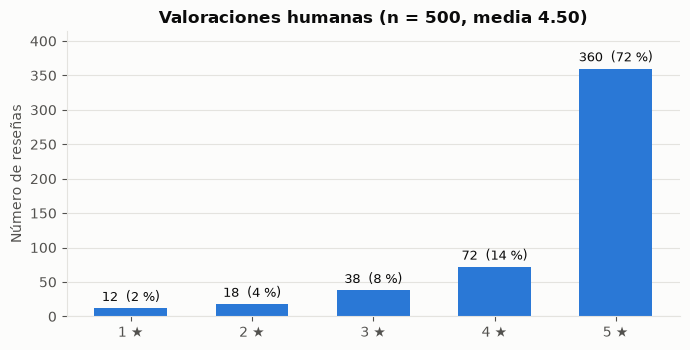

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.6))
bars = ax.bar(rating_counts.index, rating_counts.values, color=COLORS["blue"], width=0.6)
ax.bar_label(bars, labels=[f"{n}  ({p:.0f} %)" for n, p in zip(rating_counts, rating_table["porcentaje"])],
             padding=3, color=COLORS["text"], fontsize=9)
ax.set_xticks([1, 2, 3, 4, 5], labels=[f"{i} ★" for i in range(1, 6)])
ax.set_ylabel("Número de reseñas")
ax.set_title(f"Valoraciones humanas (n = {len(df_raw)}, media {rating_mean:.2f})")
ax.set_ylim(0, rating_counts.max() * 1.15)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

**Conclusión.** La media real es exactamente **4,50** y la mediana **5**. La distribución está muy concentrada: 72 % de reseñas de 5 estrellas y 86,4 % de 4–5 estrellas; solo un 6 % tiene 1–2 estrellas.
Si el modelo funciona razonablemente bien, deberíamos esperar una mayoría clara de sentimiento positivo y una minoría pequeña de negativo.

### 1.4 Longitud de los textos

La longitud importa por dos motivos: los modelos BERT tienen un límite de 512 *tokens* y los textos muy cortos o muy largos suelen ser más difíciles de clasificar.

In [7]:
lengths = pd.DataFrame({
    "caracteres": text.str.len(),
    "palabras": text.str.split().str.len(),
    "frases": text.str.count(r"[.!?](?:\s|$)"),
})
display(lengths.describe().round(1).T)

by_rating = lengths.assign(rating=df_raw["rating"]).groupby("rating").mean().round(1)
by_rating

,count,mean,std,min,25%,50%,75%,max
caracteres,500.0,170.2,27.1,86.0,155.0,173.0,189.0,230.0
palabras,500.0,29.1,4.8,14.0,26.0,29.0,32.0,42.0
frases,500.0,4.2,0.6,3.0,4.0,4.0,5.0,5.0


,caracteres,palabras,frases
rating,,,
1,175.3,30.2,4.6
2,151.3,26.4,3.9
3,152.7,26.8,3.9
4,182.3,30.5,3.9
5,170.4,29.2,4.3


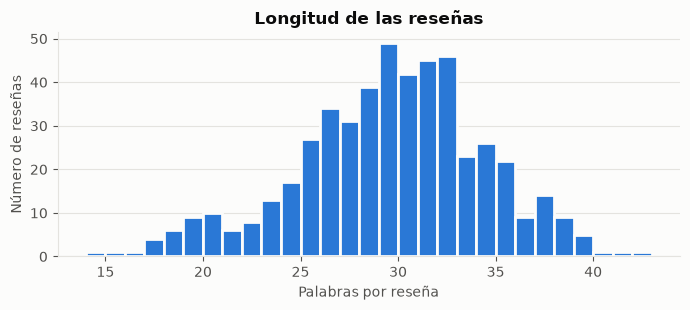

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(lengths["palabras"], bins=range(lengths["palabras"].min(), lengths["palabras"].max() + 2),
        color=COLORS["blue"], edgecolor=COLORS["surface"], linewidth=2)
ax.set_xlabel("Palabras por reseña")
ax.set_ylabel("Número de reseñas")
ax.set_title("Longitud de las reseñas")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

**Conclusión.** Las reseñas son cortas y homogéneas (≈ 30 palabras, máximo 230 caracteres, 3–5 frases). Están muy por debajo del límite de 512 tokens de BERT, así que **no habrá truncamiento** (se verificará con el tokenizador real en la sección 4). La longitud apenas varía con el rating (las de 2–3 estrellas son incluso algo más cortas), así que no es una variable que explique el sentimiento por sí sola.

### 1.5 Muestra de reseñas

Una reseña al azar por nivel de valoración, para conocer el tono y el vocabulario.

In [9]:
sample = df_raw.groupby("rating").sample(1, random_state=RANDOM_STATE).sort_values("rating")
sample[["review_id", "rating", "review_text"]]

,review_id,rating,review_text
441,442,1,Visited Harbor House Café last weekend. The coffee tasted burnt. The cashier was rude when i asked about the menu. The place felt cramped and chaotic. Not sure I'll be returning.
194,195,2,Grabbed a quick coffee at Harbor House Café this morning. The food was bland and overpriced. Our server got our order wrong twice. Probably won't recommend it to friends.
479,480,3,"Visited Harbor House Café last weekend. Average sandwiches, nothing to write home about. The staff seemed annoyed to be there. Might give it another shot."
323,324,4,"Came to Harbor House Café for a birthday brunch. The food was absolutely delicious. We waited 25 minutes just to get water, but overall a solid experience. It's fine for a quick stop."
143,144,5,The music and decor set the perfect mood. Best brunch i've had in months. Five stars without hesitation.


### 1.6 Estructura de los textos: frases recurrentes

Al leer la muestra se observan frases que se repiten literalmente entre reseñas («Visited Harbor House Café last weekend.», «Five stars without hesitation.»…).
Lo cuantificamos, porque condiciona el análisis de errores: si el modelo interpreta mal una frase, el error se repetirá en todas las reseñas que la contengan.

In [10]:
SENTENCE_SPLIT = re.compile(r"(?<=[.!?])\s+")
sentences = (df_raw.assign(sentence=text.str.strip().apply(SENTENCE_SPLIT.split))
             .explode("sentence")[["review_id", "rating", "sentence"]])

n_unique = sentences["sentence"].nunique()
print(f"Frases totales: {len(sentences)} | Frases distintas: {n_unique} | "
      f"Repetición media por frase: {len(sentences) / n_unique:.1f}")

top_sentences = (sentences.groupby("sentence")
                 .agg(apariciones=("review_id", "size"), rating_medio=("rating", "mean"))
                 .sort_values("apariciones", ascending=False)
                 .round(2))
top_sentences.head(12)

Frases totales: 2108 | Frases distintas: 69 | Repetición media por frase: 30.6


,apariciones,rating_medio
sentence,,
This is now my go-to spot.,92,4.91
Will definitely be back!,85,4.87
Five stars without hesitation.,84,4.83
Came to Harbor House Café for a birthday brunch.,79,4.54
Tried Harbor House Café after seeing it recommended online.,76,4.57
Already planning my next visit.,75,4.92
Regular customer at Harbor House Café here.,74,4.26
Grabbed a quick coffee at Harbor House Café this morning.,73,4.44
Stopped by Harbor House Café for the first time.,70,4.56


**Conclusión.** Las 500 reseñas (2.108 frases) se construyen combinando solo **69 frases distintas**, que aparecen ~31 veces de media. Además, algunas frases son mixtas en sí mismas (por ejemplo, *«We waited 25 minutes just to get water, but overall a solid experience.»* en una reseña de 4 estrellas). Esto sugiere que el dataset es **sintético o plantillado**. Tiene dos consecuencias prácticas:

- Los errores del modelo no serán aleatorios: tenderán a agruparse alrededor de frases concretas.
- Los resultados deben comunicarse como representativos *de este dataset*, no necesariamente del lenguaje real y variado de los clientes.

### 1.7 Caracteres especiales y posibles datos personales

Comprobamos emojis, URLs, correos o teléfonos: los primeros pueden transmitir sentimiento; los segundos habría que protegerlos al mostrar ejemplos.

In [11]:
checks = {
    "Caracteres no ASCII (distintos de 'é')": text.str.contains(r"[^\x00-\x7Fé]").sum(),
    "Emojis": text.str.contains(r"[\U0001F300-\U0001FAFF\u2600-\u27BF]").sum(),
    "URLs": text.str.contains(r"https?://|www\.", case=False).sum(),
    "Correos electrónicos": text.str.contains(r"[\w.+-]+@[\w-]+\.\w+").sum(),
    "Posibles teléfonos (≥ 7 dígitos)": text.str.contains(r"(?:\d[\s-]?){7,}").sum(),
    "Menciones (@usuario)": text.str.contains(r"(?<!\w)@\w+").sum(),
    "Exclamaciones": text.str.contains("!").sum(),
}
pd.Series(checks, name="reseñas afectadas").to_frame()

,reseñas afectadas
Caracteres no ASCII (distintos de 'é'),0
Emojis,0
URLs,0
Correos electrónicos,0
Posibles teléfonos (≥ 7 dígitos),0
Menciones (@usuario),0
Exclamaciones,85


**Conclusión.** El único carácter no ASCII es la «é» de «Café», correctamente codificada en UTF-8. No hay emojis, URLs, correos, teléfonos ni menciones: **no se detectan datos personales**, por lo que los ejemplos pueden mostrarse literalmente.

## 2. Insights y propuesta de limpieza

### Insights accionables

1. **La premisa del cliente se confirma en los datos:** la media real es 4,50 y el 86,4 % de las reseñas tiene 4–5 estrellas. Es la referencia contra la que compararemos el sentimiento del texto.
2. **Las clases están muy desequilibradas.** Con solo 30 reseñas de 1–2 estrellas, unos pocos errores del modelo pueden duplicar el porcentaje de «negativas». Hay que mirar los recuentos absolutos, no solo porcentajes.
3. **El texto está en inglés y es corto.** El modelo multilingüe lo admite y no habrá truncamiento; no hace falta traducción ni segmentación.
4. **El dataset es plantillado.** El análisis de errores se hará también **a nivel de frase**, porque una sola frase mal interpretada puede explicar muchas discordancias.

### ¿Hace falta limpiar los textos?

**No.** El dataset no presenta problemas que justifiquen una limpieza:

- No hay nulos, vacíos, espacios sobrantes, HTML, URLs ni problemas de codificación.
- Signos de puntuación, mayúsculas y expresiones como *«Five stars without hesitation»* o *«nothing to write home about»* **transmiten sentimiento**. Eliminarlos (stop-words, puntuación, lematización) empobrecería la entrada de un modelo BERT, que fue entrenado con texto natural.
- El modelo es *uncased* y su tokenizador ya pasa el texto a minúsculas internamente.

**Decisión:** el modelo recibirá `review_text` **tal cual**. No se eliminan filas (tampoco los 7 textos repetidos) y `df_raw` permanece intacto para garantizar la trazabilidad entre cada reseña y su predicción.

## 3. Plan de acción y justificación del modelo

### 3.1 Problema que queremos resolver

La media de 4,50 estrellas dice *cuánto* valoraron los clientes su visita, pero no describe el tono de lo que escribieron. Una reseña de 4 estrellas puede contener una queja concreta («esperamos 25 minutos»), y una de 5 puede ser escueta.
Queremos saber si **el sentimiento del texto refuerza o contradice la valoración numérica**, y en qué casos concretos lo hace.

### 3.2 Modelo seleccionado: `nlptown/bert-base-multilingual-uncased-sentiment`

- **Preentrenado y ajustado:** parte de BERT multilingüe (entrenado con texto de Wikipedia en 100+ idiomas) y fue ajustado (*fine-tuning*) para predecir sentimiento a partir de reseñas. No hace falta entrenar nada.
- **Arquitectura BERT:** un *transformer* que lee la frase completa en ambos sentidos a la vez, de modo que cada palabra se interpreta en su contexto («not bad» ≠ «bad»). Es *uncased*: no distingue mayúsculas.
- **Multilingüe:** admite inglés, neerlandés, alemán, francés, español e italiano. Nuestras reseñas están en inglés.
- **Salida ordinal de 5 niveles:** predice de **1 a 5 estrellas**, la misma escala que usan los clientes. Esto permite comparar directamente predicción y rating humano.
- **Coste:** ≈ 167 M de parámetros. En CPU procesa 500 reseñas cortas en segundos o pocos minutos, sin GPU.

La revisión del repositorio de Hugging Face se **fija a un commit concreto**, para que el resultado no cambie si los autores actualizan el modelo.

### 3.3 Limitaciones conocidas (hipótesis a contrastar)

El modelo fue ajustado con **reseñas de productos** (comercio electrónico), mientras que aquí analizamos **reseñas de un servicio** (personal, esperas, ambiente). Este desajuste de dominio *podría* provocar:

| Posible efecto | Ejemplo hipotético |
|---|---|
| Tono mal interpretado | Vocabulario de hostelería poco frecuente en reseñas de productos. |
| Experiencias mixtas leídas como negativas | «La comida, deliciosa; el servicio, lento» → el modelo podría quedarse con la queja. |
| Esperas sobredimensionadas | «Esperamos 25 minutos, pero mereció la pena» podría pesar como un defecto grave. |
| Dificultad para ponderar aspectos | Una reseña con tres elogios y una queja breve podría quedar en 2–3 estrellas. |

Son **hipótesis**: se aceptarán o descartarán con los resultados de las secciones 6 y 7, no se dan por demostradas.

### 3.4 Estrategia de clasificación

Las 5 estrellas predichas se agrupan en tres bandas de sentimiento:

| Estrellas predichas | Sentimiento |
|---|---|
| 1–2 | **Negativo** |
| 3 | **Neutral** |
| 4–5 | **Positivo** |

Para comparar en igualdad de condiciones, la misma regla se aplica al rating humano cuando hace falta hablar de «banda humana».

### 3.5 Estrategia de validación

No existe una etiqueta de sentimiento independiente: el rating humano **no es** la verdad sobre el tono del texto (alguien puede poner 5 estrellas y mencionar un problema). Por eso la validación se hace en capas:

1. **Comparación cuantitativa:** rating humano frente a estrellas predichas (diferencia media, acuerdo exacto, acuerdo ±1, tabla cruzada) y banda humana frente a banda predicha.
2. **Discordancias:** reseñas con rating humano 4–5 y predicción 1–2. Se identifican automáticamente.
3. **Revisión semántica:** cada discordancia se lee y se clasifica como *falso negativo confirmado*, *reseña genuinamente mixta* o *caso ambiguo*.
4. **Muestra de control manual (15–20 reseñas)** estratificada por banda predicha y por tipo de caso.

> **Discordancia numérica ≠ falso negativo.** Una predicción de 2 estrellas con rating humano de 5 merece revisión, pero no demuestra por sí sola que el texto sea positivo: puede que el cliente puntuara alto aunque escribiera una queja. Solo tras leer el texto se puede hablar de error del modelo.

## 4. Inferencia con Hugging Face

### 4.1 Configuración

Centralizamos el identificador del modelo, su **revisión fijada** (commit del repositorio en Hugging Face), el tamaño de lote y el dispositivo. Los pesos se descargan a la caché local de Hugging Face (`~/.cache/huggingface`), **nunca** al repositorio.

In [12]:
import time
import warnings

import huggingface_hub
import torch
import transformers
from transformers import pipeline

MODEL_NAME = "nlptown/bert-base-multilingual-uncased-sentiment"
MODEL_REVISION = "8f6f4e3a8f70be4b65d3a4a8762b6d781cda240d"   # commit del 2025-01-02 en Hugging Face
BATCH_SIZE = 32
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Salida limpia en el notebook: sin barras de descarga ni avisos de enlaces simbólicos de Windows.
huggingface_hub.utils.disable_progress_bars()
transformers.utils.logging.disable_progress_bar()
warnings.filterwarnings("ignore", message=".*symlinks.*")

print(f"torch {torch.__version__} | transformers {transformers.__version__} | dispositivo: {DEVICE}")

torch 2.15.0+cpu | transformers 5.24.1 | dispositivo: cpu


### 4.2 Acceso al modelo

Comprobamos que la revisión fijada existe y es accesible **antes** de cargarla. Si Hugging Face no respondiera, la celda fallaría con un mensaje claro: no se simulan resultados.

In [13]:
try:
    info = huggingface_hub.model_info(MODEL_NAME, revision=MODEL_REVISION)
except Exception as exc:
    raise RuntimeError(f"No se puede acceder a {MODEL_NAME}@{MODEL_REVISION}: {exc}") from exc

print("Revisión:", info.sha)
print("Tarea:", info.pipeline_tag, "| Licencia:", info.card_data.get("license") if info.card_data else "n/d")

Revisión: 8f6f4e3a8f70be4b65d3a4a8762b6d781cda240d
Tarea: text-classification | Licencia: mit


### 4.3 Carga del pipeline (una sola vez)

`pipeline("text-classification")` encapsula tres pasos: **tokenizador** (texto → identificadores numéricos), **modelo** (identificadores → 5 puntuaciones) y **post-procesado** (softmax → etiqueta con mayor probabilidad). Se instancia **una vez** y se reutiliza para todas las reseñas.

In [14]:
t0 = time.perf_counter()
classifier = pipeline(
    "text-classification",
    model=MODEL_NAME,
    revision=MODEL_REVISION,
    device=DEVICE,
)
print(f"Pipeline cargado en {time.perf_counter() - t0:.1f} s")
print("Etiquetas del modelo (id2label):", classifier.model.config.id2label)

Pipeline cargado en 1.2 s
Etiquetas del modelo (id2label): {0: '1 star', 1: '2 stars', 2: '3 stars', 3: '4 stars', 4: '5 stars'}


### 4.4 Formato real de la salida

No suponemos el formato: lo inspeccionamos sobre tres reseñas reales. Con `top_k=None` vemos además las cinco puntuaciones de una reseña.

In [15]:
probe = df_raw["review_text"].head(3).tolist()
for review, output in zip(probe, classifier(probe)):
    print(output, "<-", review[:70], "...")

print("\nDistribución completa para la primera reseña:")
classifier(probe[0], top_k=None)

{'label': '5 stars', 'score': 0.7169584035873413} <- Visited Harbor House Café last weekend. Great spot to work or catch up ...
{'label': '5 stars', 'score': 0.9822201728820801} <- Tried Harbor House Café after seeing it recommended online. The coffee ...
{'label': '5 stars', 'score': 0.6623233556747437} <- Tried Harbor House Café after seeing it recommended online. Great spot ...

Distribución completa para la primera reseña:


[{'label': '5 stars', 'score': 0.7169584035873413},
 {'label': '4 stars', 'score': 0.20376873016357422},
 {'label': '3 stars', 'score': 0.03645458444952965},
 {'label': '1 star', 'score': 0.022396886721253395},
 {'label': '2 stars', 'score': 0.020421462133526802}]

Cada predicción es un diccionario `{'label': 'N star(s)', 'score': p}`. El `score` es la probabilidad *softmax* de la clase elegida: indica cuánto se inclina el modelo por esa clase frente a las otras cuatro, **no** la probabilidad calibrada de que la predicción sea correcta.

### 4.5 Conversión de etiquetas a estrellas y bandas

La conversión es estricta: si el modelo devolviera una etiqueta inesperada, se lanza un error en lugar de asignar un valor por defecto. Se verifica contra **todas** las etiquetas que declara el modelo.

In [16]:
LABEL_PATTERN = re.compile(r"^\s*([1-5])\s+stars?\s*$", re.IGNORECASE)
SENTIMENT_ORDER = ["Negativo", "Neutral", "Positivo"]


def label_to_stars(label: str) -> int:
    """'1 star' / '4 stars' -> 1 / 4. Lanza ValueError ante cualquier otro formato."""
    match = LABEL_PATTERN.match(str(label))
    if not match:
        raise ValueError(f"Etiqueta de modelo no reconocida: {label!r}")
    return int(match.group(1))


def stars_to_sentiment(stars: int) -> str:
    """1–2 -> Negativo, 3 -> Neutral, 4–5 -> Positivo."""
    if stars in (1, 2):
        return "Negativo"
    if stars == 3:
        return "Neutral"
    if stars in (4, 5):
        return "Positivo"
    raise ValueError(f"Estrellas fuera de rango: {stars!r}")


label_check = pd.DataFrame(
    [(label, label_to_stars(label), stars_to_sentiment(label_to_stars(label)))
     for label in classifier.model.config.id2label.values()],
    columns=["etiqueta_modelo", "estrellas", "sentimiento"],
)
assert label_check["estrellas"].tolist() == [1, 2, 3, 4, 5]
label_check

,etiqueta_modelo,estrellas,sentimiento
0,1 star,1,Negativo
1,2 stars,2,Negativo
2,3 stars,3,Neutral
3,4 stars,4,Positivo
4,5 stars,5,Positivo


### 4.6 Longitud en tokens

Verificamos con el tokenizador real que ninguna reseña supera el máximo del modelo; si alguna lo hiciera, `truncation=True` la recortaría y quedaría registrado.

In [17]:
texts = df_raw["review_text"].tolist()
n_tokens = pd.Series([len(ids) for ids in classifier.tokenizer(texts)["input_ids"]], name="tokens")
max_len = classifier.tokenizer.model_max_length
print(f"Tokens por reseña: mín {n_tokens.min()} | media {n_tokens.mean():.1f} | máx {n_tokens.max()} "
      f"(límite del modelo: {max_len})")
print("Reseñas que se truncarían:", int((n_tokens > max_len).sum()))

Tokens por reseña: mín 20 | media 40.7 | máx 59 (límite del modelo: 512)
Reseñas que se truncarían: 0


### 4.7 Inferencia sobre todas las reseñas

Una única llamada al pipeline con la lista completa: internamente procesa lotes de 32 reseñas. Las entradas vacías se habrían marcado y excluido de la llamada **sin eliminar la fila**; en este dataset no hay ninguna.

In [18]:
valid_mask = df_raw["review_text"].fillna("").str.strip().ne("")
print(f"Reseñas válidas para inferencia: {valid_mask.sum()} de {len(df_raw)}")

t0 = time.perf_counter()
try:
    raw_predictions = classifier(df_raw.loc[valid_mask, "review_text"].tolist(),
                                 batch_size=BATCH_SIZE, truncation=True)
except Exception as exc:
    raise RuntimeError(f"Fallo durante la inferencia: {exc}") from exc
elapsed = time.perf_counter() - t0
print(f"Inferencia completada en {elapsed:.1f} s ({len(raw_predictions) / elapsed:.0f} reseñas/s)")

# df_pred = copia del original + columnas derivadas. El orden y el review_id se conservan.
df_pred = df_raw.copy()
df_pred.loc[valid_mask, "model_label"] = [p["label"] for p in raw_predictions]
df_pred.loc[valid_mask, "model_score"] = [round(p["score"], 4) for p in raw_predictions]
df_pred["predicted_stars"] = df_pred["model_label"].map(label_to_stars).astype("Int64")
df_pred["sentiment"] = pd.Categorical(df_pred["predicted_stars"].map(stars_to_sentiment),
                                      categories=SENTIMENT_ORDER, ordered=True)
df_pred.head()

Reseñas válidas para inferencia: 500 de 500


Inferencia completada en 20.8 s (24 reseñas/s)


,review_id,rating,review_text,model_label,model_score,predicted_stars,sentiment
0,1,5,Visited Harbor House Café last weekend. Great spot to work or catch up with friends. Every dish was bursting with flavor. Worth every penny. Already planning my next visit.,5 stars,0.7170,5,Positivo
1,2,5,Tried Harbor House Café after seeing it recommended online. The coffee was rich and perfectly brewed. Great spot to work or catch up with friends. Great value for what you get. Five stars without hesitation.,5 stars,0.9822,5,Positivo
2,3,5,Tried Harbor House Café after seeing it recommended online. Great spot to work or catch up with friends. The seasonal menu never disappoints. Great value for what you get. Already planning my next visit.,5 stars,0.6623,5,Positivo
3,4,5,Visited Harbor House Café last weekend. The staff were warm and attentive. The music and decor set the perfect mood. Worth every penny. Five stars without hesitation.,5 stars,0.9895,5,Positivo
4,5,5,Grabbed a quick coffee at Harbor House Café this morning. They went out of their way to accommodate my allergy. The food was absolutely delicious. Five stars without hesitation.,5 stars,0.9829,5,Positivo


### 4.8 Validaciones

Cada comprobación es un `assert`: si alguna fallara, el notebook se detendría aquí en lugar de seguir con datos incorrectos.

In [19]:
expected_band = df_pred["predicted_stars"].map({1: "Negativo", 2: "Negativo", 3: "Neutral", 4: "Positivo", 5: "Positivo"})
validations = {
    "Registros de entrada = registros con predicción": len(df_raw) == len(df_pred) == len(raw_predictions),
    "review_id idéntico y en el mismo orden": df_pred["review_id"].equals(df_raw["review_id"]),
    "Texto original sin modificar": df_pred["review_text"].equals(df_raw["review_text"]),
    "Rating original sin modificar": df_pred["rating"].equals(df_raw["rating"]),
    "Sin predicciones nulas": df_pred[["model_label", "model_score", "predicted_stars", "sentiment"]].notna().all().all(),
    "Columnas esenciales presentes": {"review_id", "rating", "review_text", "predicted_stars", "sentiment"} <= set(df_pred.columns),
    "predicted_stars dentro de 1–5": df_pred["predicted_stars"].between(1, 5).all(),
    "Bandas válidas": df_pred["sentiment"].isin(SENTIMENT_ORDER).all(),
    "Banda coherente con las estrellas": (df_pred["sentiment"].astype(str) == expected_band).all(),
    "Sin duplicados introducidos": not df_pred["review_id"].duplicated().any(),
    "Scores en (0, 1]": df_pred["model_score"].between(0, 1, inclusive="right").all(),
}
validation_table = pd.Series(validations, name="OK").to_frame()
assert validation_table["OK"].all(), validation_table[~validation_table["OK"]]
validation_table

,OK
Registros de entrada = registros con predicción,True
review_id idéntico y en el mismo orden,True
Texto original sin modificar,True
Rating original sin modificar,True
Sin predicciones nulas,True
Columnas esenciales presentes,True
predicted_stars dentro de 1–5,True
Bandas válidas,True
Banda coherente con las estrellas,True
Sin duplicados introducidos,True


**Resultado.** Las 500 reseñas tienen predicción, conservan su `review_id`, su texto y su rating originales, y cada predicción se traduce de forma verificable a una banda de sentimiento. `df_pred` es la tabla de trabajo para el resto del análisis.

## 5. Distribución de sentimiento frente a las estrellas

### 5.1 ¿Cuántas reseñas son positivas, neutrales y negativas?

El denominador es el total de reseñas del dataset (500), todas con predicción.

In [20]:
N = len(df_pred)
sentiment_counts = df_pred["sentiment"].value_counts().reindex(SENTIMENT_ORDER)
sentiment_table = pd.DataFrame({
    "reseñas": sentiment_counts,
    "porcentaje": (sentiment_counts / N * 100).round(1),
})
sentiment_table.loc["Total"] = [sentiment_table["reseñas"].sum(), sentiment_table["porcentaje"].sum().round(1)]
assert sentiment_table.loc["Total", "reseñas"] == N
sentiment_table

,reseñas,porcentaje
sentiment,,
Negativo,47,9.4
Neutral,41,8.2
Positivo,412,82.4
Total,500,100.0


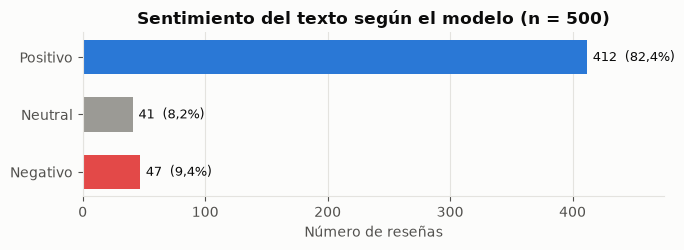

In [21]:
fig, ax = plt.subplots(figsize=(7, 2.6))
band_colors = [COLORS["negative"], COLORS["neutral"], COLORS["positive"]]
bars = ax.barh(SENTIMENT_ORDER, sentiment_counts.values, color=band_colors, height=0.6)
ax.bar_label(bars, labels=[f"{n}  ({n / N:.1%})".replace(".", ",") for n in sentiment_counts],
             padding=4, color=COLORS["text"], fontsize=9)
ax.set_xlim(0, N * 0.95)
ax.set_xlabel("Número de reseñas")
ax.set_title(f"Sentimiento del texto según el modelo (n = {N})")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

### 5.2 Estrellas humanas frente a estrellas predichas

Calculamos la media y la mediana reales del CSV y las comparamos con la referencia de 4,5 y con la media de las estrellas que predice el modelo.

In [22]:
stars_summary = pd.DataFrame({
    "rating humano": [df_pred["rating"].mean(), df_pred["rating"].median()],
    "estrellas predichas": [df_pred["predicted_stars"].astype(float).mean(), df_pred["predicted_stars"].astype(float).median()],
}, index=["media", "mediana"]).round(2)
stars_summary["diferencia (modelo − humano)"] = stars_summary["estrellas predichas"] - stars_summary["rating humano"]

print(f"Media humana {df_pred['rating'].mean():.2f} vs referencia {REFERENCE_RATING}: "
      f"diferencia {df_pred['rating'].mean() - REFERENCE_RATING:+.2f}")
stars_summary

Media humana 4.50 vs referencia 4.5: diferencia +0.00


,rating humano,estrellas predichas,diferencia (modelo − humano)
media,4.5,4.4,-0.1
mediana,5.0,5.0,0.0


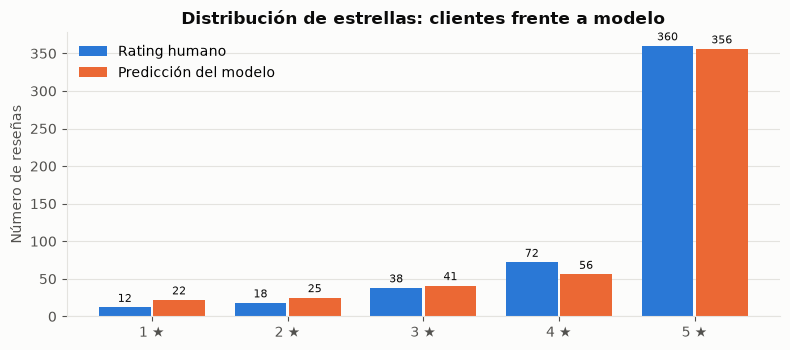

In [23]:
human_dist = df_pred["rating"].value_counts().reindex(range(1, 6), fill_value=0)
model_dist = df_pred["predicted_stars"].value_counts().reindex(range(1, 6), fill_value=0)

fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(1, 6)
w = 0.38
b1 = ax.bar(x - w / 2 - 0.01, human_dist.values, w, color=COLORS["blue"], label="Rating humano")
b2 = ax.bar(x + w / 2 + 0.01, model_dist.values, w, color=COLORS["orange"], label="Predicción del modelo")
ax.bar_label(b1, padding=2, fontsize=8, color=COLORS["text"])
ax.bar_label(b2, padding=2, fontsize=8, color=COLORS["text"])
ax.set_xticks(x, labels=[f"{i} ★" for i in x])
ax.set_ylabel("Número de reseñas")
ax.set_title("Distribución de estrellas: clientes frente a modelo")
ax.legend(frameon=False, loc="upper left")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

### 5.3 Tabla cruzada: ¿dónde coinciden y dónde no?

Cada celda cuenta cuántas reseñas con un rating humano (filas) recibieron una predicción concreta (columnas). La diagonal son coincidencias exactas; la esquina inferior izquierda (rating alto, predicción baja) es la zona de posibles falsos negativos. El color usa escala logarítmica para que las celdas pequeñas sigan siendo visibles junto a la de 335.

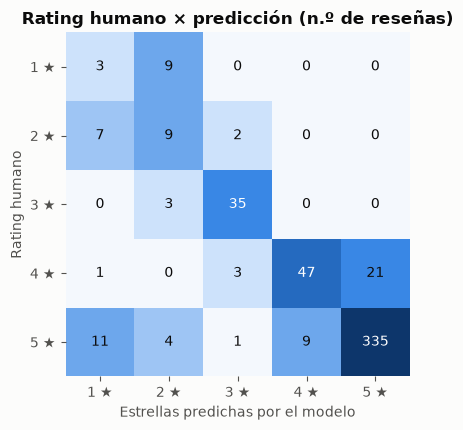

In [24]:
crosstab = pd.crosstab(df_pred["rating"], df_pred["predicted_stars"]).reindex(index=range(1, 6), columns=range(1, 6), fill_value=0)

from matplotlib.colors import ListedColormap
blues = ListedColormap(["#f4f8fd", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])

fig, ax = plt.subplots(figsize=(5.6, 4.4))
im = ax.imshow(np.log1p(crosstab.values), cmap=blues)
for i in range(5):
    for j in range(5):
        v = crosstab.values[i, j]
        ax.text(j, i, v, ha="center", va="center", fontsize=10,
                color="white" if np.log1p(v) > np.log1p(crosstab.values.max()) * 0.55 else COLORS["text"])
ax.set_xticks(range(5), labels=[f"{i} ★" for i in range(1, 6)])
ax.set_yticks(range(5), labels=[f"{i} ★" for i in range(1, 6)])
ax.set_xlabel("Estrellas predichas por el modelo")
ax.set_ylabel("Rating humano")
ax.set_title("Rating humano × predicción (n.º de reseñas)")
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
plt.tight_layout()
plt.show()

In [25]:
df_pred["human_band"] = pd.Categorical(df_pred["rating"].map(stars_to_sentiment), categories=SENTIMENT_ORDER, ordered=True)
diff = df_pred["predicted_stars"].astype(int) - df_pred["rating"]

agreement = pd.Series({
    "Coincidencia exacta de estrellas": (diff == 0).mean(),
    "Coincidencia a ±1 estrella": (diff.abs() <= 1).mean(),
    "Coincidencia de banda de sentimiento": (df_pred["human_band"] == df_pred["sentiment"]).mean(),
    "Predicción más baja que el rating": (diff < 0).mean(),
    "Predicción más alta que el rating": (diff > 0).mean(),
}).mul(100).round(1).rename("% de reseñas").to_frame()
agreement.loc["Error absoluto medio (estrellas)"] = round(diff.abs().mean(), 2)
display(agreement)

band_crosstab = pd.crosstab(df_pred["human_band"], df_pred["sentiment"], margins=True, margins_name="Total")
band_crosstab.index.name, band_crosstab.columns.name = "banda humana", "banda del modelo"
band_crosstab

,% de reseñas
Coincidencia exacta de estrellas,85.80
Coincidencia a ±1 estrella,96.60
Coincidencia de banda de sentimiento,95.00
Predicción más baja que el rating,7.80
Predicción más alta que el rating,6.40
Error absoluto medio (estrellas),0.23


banda del modelo,Negativo,Neutral,Positivo,Total
banda humana,,,,
Negativo,28,2,0,30
Neutral,3,35,0,38
Positivo,16,4,412,432
Total,47,41,412,500


### 5.4 Lectura de los resultados

- **Predomina el sentimiento positivo:** el modelo clasifica como positivas **412 de 500 reseñas (82,4 %)**, frente a 41 neutrales (8,2 %) y 47 negativas (9,4 %).
- **Es coherente con una media de 4,5**, aunque algo más pesimista: según las estrellas humanas, el 86,4 % de las reseñas estarían en la banda positiva y el 6,0 % en la negativa. El modelo **traslada unas 20 reseñas de la banda positiva a la neutral o negativa** (16 a negativa y 4 a neutral) y su media de estrellas predichas (4,40) queda 0,10 por debajo de la humana (4,50).
- **El acuerdo es alto, pero no perfecto:** coinciden exactamente las estrellas en el 85,8 % de los casos y la banda en el 95 %. Los desacuerdos van casi siempre en la misma dirección: el modelo **nunca** clasifica como positiva una reseña de 1–3 estrellas, pero sí clasifica como negativas 16 reseñas de 4–5 estrellas.
- **Qué podemos concluir:** el texto de las reseñas respalda la imagen de un negocio muy bien valorado; no aparece un descontento oculto tras las estrellas.
- **Qué no podemos concluir todavía:** que los 47 «negativos» del modelo sean quejas reales. La celda *rating 5 → predicción 1* (11 reseñas) es anómala y se investiga en la sección 6. Tampoco es válido convertir porcentajes de sentimiento en una media de estrellas: son escalas distintas.

## 6. Discordancias y falsos negativos

### 6.1 Definición operativa

Una **discordancia** es una reseña con **rating humano 4–5** y **predicción 1–2**. Es una señal cuantitativa que merece revisión, no un error demostrado.
Solo tras leer el texto la clasificamos como:

| Categoría | Criterio |
|---|---|
| **Falso negativo confirmado** | El texto es claramente favorable y no contiene quejas: el modelo se equivoca. |
| **Reseña genuinamente mixta** | El texto combina elogios y una queja explícita; el tono global sigue siendo favorable, pero la queja existe. |
| **Caso ambiguo** | El texto admite varias lecturas razonables. |

In [26]:
is_discordant = (df_pred["rating"] >= 4) & (df_pred["predicted_stars"] <= 2)
discordances = df_pred.loc[is_discordant, ["review_id", "rating", "predicted_stars", "sentiment", "model_score", "review_text"]]
n_high = int((df_pred["rating"] >= 4).sum())

print(f"Discordancias: {len(discordances)} | {len(discordances) / N:.1%} del total ({N}) | "
      f"{len(discordances) / n_high:.1%} de las reseñas con rating 4–5 ({n_high})")
print(f"Score mediano del modelo — discordancias: {discordances['model_score'].median():.2f} | "
      f"resto: {df_pred.loc[~is_discordant, 'model_score'].median():.2f}")
discordances

Discordancias: 16 | 3.2% del total (500) | 3.7% de las reseñas con rating 4–5 (432)
Score mediano del modelo — discordancias: 0.36 | resto: 0.71


,review_id,rating,predicted_stars,sentiment,model_score,review_text
13,14,4,1,Negativo,0.4443,Tried Harbor House Café after seeing it recommended online. Every dish was bursting with flavor. The team clearly cares about the customers. Already planning my next visit.
14,15,5,1,Negativo,0.3893,"Every dish was bursting with flavor. The place has such a cozy, welcoming vibe. Already planning my next visit."
72,73,5,1,Negativo,0.2679,Stopped by Harbor House Café for the first time. Service was fast and friendly. Every dish was bursting with flavor. Worth every penny. Already planning my next visit.
86,87,5,1,Negativo,0.3247,Tried Harbor House Café after seeing it recommended online. The seasonal menu never disappoints. They went out of their way to accommodate my allergy. Will definitely be back!
137,138,5,2,Negativo,0.2751,"Tried Harbor House Café after seeing it recommended online. They went out of their way to accommodate my allergy. The place has such a cozy, welcoming vibe. Already planning my next visit."
199,200,5,2,Negativo,0.3685,Stopped by Harbor House Café for the first time. The music and decor set the perfect mood. Every dish was bursting with flavor. Already planning my next visit.
203,204,5,1,Negativo,0.3492,"Came to Harbor House Café for a birthday brunch. Every dish was bursting with flavor. The cashier was rude when i asked about the menu, but honestly the food made up for it. Already planning my next visit."
253,254,5,1,Negativo,0.3641,Stopped by Harbor House Café for the first time. They went out of their way to accommodate my allergy. Great spot to work or catch up with friends. Will definitely be back!
269,270,5,1,Negativo,0.4091,Stopped by Harbor House Café for the first time. Our server remembered our names by the second visit. Every dish was bursting with flavor. Great value for what you get. Will definitely be back!
321,322,5,1,Negativo,0.6077,"Every dish was bursting with flavor. The staff seemed annoyed to be there, but honestly the food made up for it. Will definitely be back!"


Las 16 discordancias tienen una confianza baja (score mediano ≈ 0,37 frente a ≈ 0,7 en el resto): el modelo «duda» en estos casos, y aun así elige 1–2 estrellas.

### 6.2 Temas presentes en las discordancias

Comparamos, **dentro de las reseñas con rating 4–5**, la tasa de discordancia de las que mencionan cada tema con la tasa base (3,7 %). Una tasa mucho mayor indica asociación, **no causalidad**.

In [27]:
THEMES = {
    "Esperas / lentitud": r"\bwait|\bslow\b|minutes",
    "Problema puntual de servicio": r"rude|annoyed|wrong twice|nobody checked|came out cold",
    "Comentario mixto («but…»)": r"\bbut\b",
    "Personal y atención": r"staff|server|team|cashier|service",
    "Ambiente del local": r"vibe|decor|music|natural light|plants|cozy|loud|cramped|spot to work",
    "Negaciones y coloquialismos": r"\bnot\b|n't\b|\bnever\b|no complaints|nothing to write home|made up for it",
    "Comida: «bursting with flavor»": r"bursting with flavor",
    "Alergias / necesidades especiales": r"allerg",
}
high = df_pred[df_pred["rating"] >= 4]
high_disc = is_discordant[high.index]
base_rate = high_disc.mean()

theme_rows = []
for theme, pattern in THEMES.items():
    has = high["review_text"].str.contains(pattern, case=False, regex=True)
    theme_rows.append({
        "tema": theme,
        "reseñas 4–5 con el tema": int(has.sum()),
        "de ellas discordantes": int(high_disc[has].sum()),
        "tasa de discordancia %": round(high_disc[has].mean() * 100, 1) if has.any() else np.nan,
        "tasa sin el tema %": round(high_disc[~has].mean() * 100, 1),
    })
theme_table = pd.DataFrame(theme_rows).set_index("tema").sort_values("tasa de discordancia %", ascending=False)
print(f"Tasa base de discordancia en reseñas 4–5: {base_rate:.1%}")
theme_table

Tasa base de discordancia en reseñas 4–5: 3.7%


,reseñas 4–5 con el tema,de ellas discordantes,tasa de discordancia %,tasa sin el tema %
tema,,,,
Comida: «bursting with flavor»,41,12,29.3,1.0
Alergias / necesidades especiales,38,4,10.5,3.0
Problema puntual de servicio,27,2,7.4,3.5
Negaciones y coloquialismos,68,3,4.4,3.6
Personal y atención,266,10,3.8,3.6
Comentario mixto («but…»),90,2,2.2,4.1
Ambiente del local,231,4,1.7,6.0
Esperas / lentitud,34,0,0.0,4.0


Los temas que la hipótesis de dominio señalaba (esperas, quejas puntuales, comentarios mixtos, personal) **no** concentran las discordancias. Destacan dos expresiones concretas: *«bursting with flavor»* (29 % de discordancia) y las menciones a **alergias** (≈ 11 %). No se observa ironía en el dataset.

### 6.3 ¿Qué frases arrastran la predicción hacia abajo?

Como el dataset se compone de 69 frases, podemos pasar **cada frase por separado** por el mismo pipeline. Esto muestra cómo valora el modelo cada pieza fuera de contexto. Listamos las frases que el modelo puntúa con 1–2 estrellas pero que aparecen en reseñas de 4–5.

In [28]:
unique_sentences = sentences["sentence"].unique().tolist()
sentence_preds = classifier(unique_sentences, batch_size=BATCH_SIZE, truncation=True)
sentence_stars = pd.DataFrame({
    "sentence": unique_sentences,
    "estrellas_aislada": [label_to_stars(p["label"]) for p in sentence_preds],
    "score": [round(p["score"], 2) for p in sentence_preds],
})

disc_ids = set(discordances["review_id"])
in_high = sentences[sentences["rating"] >= 4]
sentence_usage = in_high.groupby("sentence").agg(
    reseñas_4_5=("review_id", "nunique"),
    discordantes=("review_id", lambda ids: int(ids.isin(disc_ids).sum())),
)
suspicious = (sentence_stars.merge(sentence_usage, left_on="sentence", right_index=True)
              .query("estrellas_aislada <= 2")
              .sort_values(["discordantes", "reseñas_4_5"], ascending=False))
suspicious

,sentence,estrellas_aislada,score,reseñas_4_5,discordantes
2,Every dish was bursting with flavor.,1,0.67,41,12
5,Tried Harbor House Café after seeing it recommended online.,1,0.45,68,6
15,Stopped by Harbor House Café for the first time.,1,0.62,61,6
13,They went out of their way to accommodate my allergy.,1,0.44,38,4
34,Might give it another shot.,1,0.32,7,0
67,"Nobody checked on us the entire meal, but honestly the food made up for it.",2,0.28,2,0


Entre las frases presentes en las discordancias, cuatro **favorables o neutras** reciben 1 estrella cuando se evalúan solas:

- *«Every dish was bursting with flavor.»* — un elogio claro.
- *«They went out of their way to accommodate my allergy.»* — un elogio al servicio.
- *«Stopped by Harbor House Café for the first time.»* y *«Tried Harbor House Café after seeing it recommended online.»* — frases introductorias sin carga emocional.

### 6.4 Prueba de ablación: quitar una frase y volver a predecir

Para pasar de la asociación a una prueba sobre el comportamiento del modelo, eliminamos **una frase cada vez** de cada discordancia y volvemos a clasificar. La frase cuya eliminación más sube la predicción es la que más está arrastrando el resultado. *(Es un diagnóstico: estas variantes no sustituyen a las predicciones oficiales.)*

In [29]:
variants = []
for _, row in discordances.iterrows():
    parts = SENTENCE_SPLIT.split(row["review_text"].strip())
    for i, removed in enumerate(parts):
        variants.append({"review_id": row["review_id"], "frase_eliminada": removed,
                         "texto_variante": " ".join(parts[:i] + parts[i + 1:])})
variants = pd.DataFrame(variants)
variant_preds = classifier(variants["texto_variante"].tolist(), batch_size=BATCH_SIZE, truncation=True)
variants["estrellas_sin_frase"] = [label_to_stars(p["label"]) for p in variant_preds]
variants = variants.merge(discordances[["review_id", "predicted_stars"]], on="review_id")
variants["cambio"] = variants["estrellas_sin_frase"] - variants["predicted_stars"].astype(int)

max_change = variants.groupby("review_id")["cambio"].transform("max")
culprits = (variants[(variants["cambio"] == max_change) & (max_change > 0)]
            .groupby("review_id")
            .agg(estrellas_originales=("predicted_stars", "first"),
                 estrellas_sin_frase=("estrellas_sin_frase", "max"),
                 frase_responsable=("frase_eliminada", " | ".join)))
print(f"Discordancias que pasan a 4–5 estrellas al quitar una sola frase: "
      f"{int((culprits['estrellas_sin_frase'] >= 4).sum())} de {len(discordances)}")
culprits

Discordancias que pasan a 4–5 estrellas al quitar una sola frase: 16 de 16


,estrellas_originales,estrellas_sin_frase,frase_responsable
review_id,,,
14,1,4,Every dish was bursting with flavor.
15,1,5,Every dish was bursting with flavor.
73,1,5,Stopped by Harbor House Café for the first time. | Every dish was bursting with flavor.
87,1,5,Tried Harbor House Café after seeing it recommended online. | They went out of their way to accommodate my allergy. | Will definitely be back!
138,2,5,Tried Harbor House Café after seeing it recommended online.
200,2,5,Stopped by Harbor House Café for the first time. | Every dish was bursting with flavor.
204,1,4,Every dish was bursting with flavor.
254,1,5,Stopped by Harbor House Café for the first time. | They went out of their way to accommodate my allergy. | Will definitely be back!
270,1,5,Stopped by Harbor House Café for the first time. | Every dish was bursting with flavor. | Will definitely be back!


In [30]:
# ¿Qué frase aparece como responsable con más frecuencia?
culprits["frase_responsable"].str.split(" \\| ").explode().value_counts().rename("discordancias").to_frame()

,discordancias
frase_responsable,
Every dish was bursting with flavor.,12
Stopped by Harbor House Café for the first time.,6
Tried Harbor House Café after seeing it recommended online.,3
They went out of their way to accommodate my allergy.,3
Will definitely be back!,3
Already planning my next visit.,1


### 6.5 Revisión semántica de las 16 discordancias

Cada texto se ha leído completo. La categoría y la nota se registran explícitamente por `review_id`; el `assert` garantiza que las anotaciones corresponden exactamente a las discordancias que produce el modelo con la revisión fijada.

> **Quién revisa:** la lectura la ha hecho el analista que construyó este notebook (en este proyecto, un agente de IA). Es una revisión cualitativa razonada, **no** un etiquetado independiente; conviene que una persona del equipo la confirme antes de entregarla al cliente.

In [31]:
FN, MIXED, AMBIG = "Falso negativo confirmado", "Reseña genuinamente mixta", "Caso ambiguo"
semantic_review = {
    14:  (FN, "Tres elogios (comida, equipo, volver) y ninguna queja."),
    15:  (FN, "Comida, ambiente y ganas de volver: texto inequívocamente positivo."),
    73:  (FN, "Servicio rápido, comida, precio y volver: sin ningún matiz negativo."),
    87:  (FN, "Menú, atención a la alergia y 'Will definitely be back!': positivo."),
    138: (FN, "Atención a la alergia y ambiente acogedor: positivo."),
    200: (FN, "Música, decoración, comida y volver: positivo."),
    204: (MIXED, "Queja explícita (cajero grosero) compensada por la comida; veredicto global favorable."),
    254: (FN, "Atención a la alergia, buen sitio, volverá: positivo."),
    270: (FN, "Servicio cercano, comida, precio y volver: positivo."),
    322: (MIXED, "Queja explícita (personal molesto) compensada por la comida; veredicto global favorable."),
    332: (FN, "Atención a la alergia y café excelente: positivo."),
    409: (FN, "Comida y servicio rápido y amable: positivo."),
    440: (FN, "Cliente habitual, comida, servicio, precio: positivo."),
    462: (FN, "Equipo atento y comida: positivo."),
    474: (FN, "Comida, servicio y 'my go-to spot': positivo."),
    489: (FN, "Comida, equipo, precio y volver: positivo."),
}
assert set(semantic_review) == disc_ids, "Las anotaciones no coinciden con las discordancias actuales"

review_6 = discordances.assign(
    categoria=discordances["review_id"].map(lambda i: semantic_review[i][0]),
    interpretacion=discordances["review_id"].map(lambda i: semantic_review[i][1]),
).merge(culprits[["frase_responsable"]], left_on="review_id", right_index=True, how="left")

display(review_6["categoria"].value_counts().rename("reseñas").to_frame())
review_6[["review_id", "rating", "predicted_stars", "sentiment", "categoria", "interpretacion", "frase_responsable"]]

,reseñas
categoria,
Falso negativo confirmado,14
Reseña genuinamente mixta,2


,review_id,rating,predicted_stars,sentiment,categoria,interpretacion,frase_responsable
13,14,4,1,Negativo,Falso negativo confirmado,"Tres elogios (comida, equipo, volver) y ninguna queja.",Every dish was bursting with flavor.
14,15,5,1,Negativo,Falso negativo confirmado,"Comida, ambiente y ganas de volver: texto inequívocamente positivo.",Every dish was bursting with flavor.
72,73,5,1,Negativo,Falso negativo confirmado,"Servicio rápido, comida, precio y volver: sin ningún matiz negativo.",Stopped by Harbor House Café for the first time. | Every dish was bursting with flavor.
86,87,5,1,Negativo,Falso negativo confirmado,"Menú, atención a la alergia y 'Will definitely be back!': positivo.",Tried Harbor House Café after seeing it recommended online. | They went out of their way to accommodate my allergy. | Will definitely be back!
137,138,5,2,Negativo,Falso negativo confirmado,Atención a la alergia y ambiente acogedor: positivo.,Tried Harbor House Café after seeing it recommended online.
199,200,5,2,Negativo,Falso negativo confirmado,"Música, decoración, comida y volver: positivo.",Stopped by Harbor House Café for the first time. | Every dish was bursting with flavor.
203,204,5,1,Negativo,Reseña genuinamente mixta,Queja explícita (cajero grosero) compensada por la comida; veredicto global favorable.,Every dish was bursting with flavor.
253,254,5,1,Negativo,Falso negativo confirmado,"Atención a la alergia, buen sitio, volverá: positivo.",Stopped by Harbor House Café for the first time. | They went out of their way to accommodate my allergy. | Will definitely be back!
269,270,5,1,Negativo,Falso negativo confirmado,"Servicio cercano, comida, precio y volver: positivo.",Stopped by Harbor House Café for the first time. | Every dish was bursting with flavor. | Will definitely be back!
321,322,5,1,Negativo,Reseña genuinamente mixta,Queja explícita (personal molesto) compensada por la comida; veredicto global favorable.,Every dish was bursting with flavor.


### 6.6 Ejemplos representativos

In [32]:
examples = review_6.set_index("review_id").loc[[15, 87, 322],
                                               ["rating", "predicted_stars", "sentiment", "review_text", "categoria", "interpretacion"]]
examples

,rating,predicted_stars,sentiment,review_text,categoria,interpretacion
review_id,,,,,,
15,5,1,Negativo,"Every dish was bursting with flavor. The place has such a cozy, welcoming vibe. Already planning my next visit.",Falso negativo confirmado,"Comida, ambiente y ganas de volver: texto inequívocamente positivo."
87,5,1,Negativo,Tried Harbor House Café after seeing it recommended online. The seasonal menu never disappoints. They went out of their way to accommodate my allergy. Will definitely be back!,Falso negativo confirmado,"Menú, atención a la alergia y 'Will definitely be back!': positivo."
322,5,1,Negativo,"Every dish was bursting with flavor. The staff seemed annoyed to be there, but honestly the food made up for it. Will definitely be back!",Reseña genuinamente mixta,Queja explícita (personal molesto) compensada por la comida; veredicto global favorable.


### 6.7 Patrones y explicación

**Lo que muestran los datos (observado):**

1. **14 de las 16 discordancias son falsos negativos confirmados**: textos enteramente elogiosos clasificados con 1–2 estrellas. Las otras 2 son reseñas mixtas con veredicto favorable. No hay casos ambiguos.
2. **Dos frases elogiosas concentran los errores.** *«Every dish was bursting with flavor.»* está en 12 de las 16 discordancias y *«…accommodate my allergy.»* en las 4 restantes. Evaluadas solas, ambas reciben 1 estrella.
3. **La ablación distingue dos mecanismos:**
   - En las **12 reseñas con *«bursting with flavor»***, quitar esa frase sube la predicción a 4–5 en **todos** los casos, mientras que quitar otros elogios no la cambia (p. ej., ids 15 y 409 siguen en 1 estrella). Es una **dependencia fuerte de una sola expresión**.
   - En las **4 reseñas con *«allergy»***, la predicción es **inestable**: quitar la frase de la alergia, la frase introductoria (*«Stopped by…»*, *«Tried…»*) o incluso otro elogio basta para subirla a 4–5. El error nace de la **combinación** de frases, con una confianza muy baja (score 0,27–0,36), no de una expresión aislada.
4. **Las quejas puntuales y las esperas no son la causa principal.** Las 2 reseñas mixtas también suben a 4 estrellas al quitar *«bursting with flavor»*, no al quitar la queja.

**Lo que sigue siendo hipótesis (no demostrado):**

- Que el origen sea el **dominio de entrenamiento**. En reseñas de productos, «bursting» suele describir defectos (envases que revientan) y «allergy» suele aparecer en quejas (reacciones alérgicas a un producto). Es una explicación verosímil, pero **no tenemos acceso a los datos de entrenamiento** para comprobarla.
- Que este patrón se repita en reseñas reales. El dataset está plantillado, así que el impacto de cada frase está amplificado: una sola expresión se repite en 41 reseñas.

**Lo que no se ha observado:** el modelo no clasifica como positiva ninguna reseña de 1–3 estrellas, y los desacuerdos restantes (9 reseñas) están a una banda de distancia y son tibios por naturaleza (por ejemplo, *«decent, nothing special»*).

## 7. Validación manual de una muestra (18 reseñas)

### 7.1 Selección de la muestra

La muestra es **estratificada y deliberadamente sesgada hacia los casos difíciles**: incluye discordancias y desacuerdos de banda en mucha mayor proporción que en el dataset. Por eso **no es representativa** del total y su tasa de acierto no debe extrapolarse.

| Estrato | Reseñas | Para qué |
|---|---|---|
| Discordancia (rating 4–5, predicción 1–2) | 4 | Comprobar los posibles falsos negativos |
| Desacuerdo de banda (resto de casos) | 3 | Casos ambiguos o adyacentes |
| Negativo concordante | 4 | ¿Detecta bien las quejas? |
| Neutral concordante | 3 | ¿Distingue lo tibio? |
| Positivo concordante | 4 | ¿Acierta lo evidente? |

La selección dentro de cada estrato es aleatoria con semilla fija (`random_state=42`).

In [33]:
MANUAL_STRATA = {
    "Discordancia (rating 4–5, predicción 1–2)": (is_discordant, 4),
    "Desacuerdo de banda (resto)": (~is_discordant & (df_pred["human_band"] != df_pred["sentiment"]), 3),
    "Negativo concordante": ((df_pred["sentiment"] == "Negativo") & (df_pred["human_band"] == "Negativo"), 4),
    "Neutral concordante": ((df_pred["sentiment"] == "Neutral") & (df_pred["human_band"] == "Neutral"), 3),
    "Positivo concordante": ((df_pred["sentiment"] == "Positivo") & (df_pred["human_band"] == "Positivo"), 4),
}
manual_sample = pd.concat([
    df_pred[mask].sample(n, random_state=RANDOM_STATE).assign(estrato=name)
    for name, (mask, n) in MANUAL_STRATA.items()
])
print(f"Reseñas en la muestra: {len(manual_sample)}")
manual_sample[["estrato", "review_id", "rating", "predicted_stars", "sentiment", "model_score", "review_text"]]

Reseñas en la muestra: 18


,estrato,review_id,rating,predicted_stars,sentiment,model_score,review_text
13,"Discordancia (rating 4–5, predicción 1–2)",14,4,1,Negativo,0.4443,Tried Harbor House Café after seeing it recommended online. Every dish was bursting with flavor. The team clearly cares about the customers. Already planning my next visit.
14,"Discordancia (rating 4–5, predicción 1–2)",15,5,1,Negativo,0.3893,"Every dish was bursting with flavor. The place has such a cozy, welcoming vibe. Already planning my next visit."
199,"Discordancia (rating 4–5, predicción 1–2)",200,5,2,Negativo,0.3685,Stopped by Harbor House Café for the first time. The music and decor set the perfect mood. Every dish was bursting with flavor. Already planning my next visit.
473,"Discordancia (rating 4–5, predicción 1–2)",474,5,1,Negativo,0.4817,Stopped by Harbor House Café for the first time. Every dish was bursting with flavor. Service was fast and friendly. This is now my go-to spot.
476,Desacuerdo de banda (resto),477,5,3,Neutral,0.2709,"Tried Harbor House Café after seeing it recommended online. The coffee was rich and perfectly brewed. We waited 25 minutes just to get water, but honestly the food made up for it. Already planning my next visit."
191,Desacuerdo de banda (resto),192,2,3,Neutral,0.6578,"Regular customer at Harbor House Café here. The food was decent, nothing special. Service was fine, nothing memorable. Just didn't love it enough to come back."
310,Desacuerdo de banda (resto),311,3,2,Negativo,0.4869,"Tried Harbor House Café after seeing it recommended online. The food was decent, nothing special. Nobody checked on us the entire meal. Might give it another shot."
122,Negativo concordante,123,1,2,Negativo,0.6548,Grabbed a quick coffee at Harbor House Café this morning. The portions were way too small for the price. We waited 25 minutes just to get water. Tables were sticky and the floor hadn't been swept. Disappointing experience overall.
441,Negativo concordante,442,1,2,Negativo,0.4583,Visited Harbor House Café last weekend. The coffee tasted burnt. The cashier was rude when i asked about the menu. The place felt cramped and chaotic. Not sure I'll be returning.
114,Negativo concordante,115,2,2,Negativo,0.6249,Grabbed a quick coffee at Harbor House Café this morning. The pastry was stale. We waited 25 minutes just to get water. Disappointing experience overall.


### 7.2 Revisión individual

Criterio conservador: **Correcta**, **Incorrecta** o **Ambigua**. Si el texto admite varias lecturas, se marca como ambigua en lugar de forzar una decisión. La revisión la ha hecho el analista que construyó el notebook (un agente de IA) leyendo cada texto completo; debe confirmarla una persona del equipo.

In [34]:
manual_review = {
    14:  ("Positivo", "Incorrecta", "Solo elogios; el error coincide con 'bursting with flavor'."),
    15:  ("Positivo", "Incorrecta", "Comida, ambiente y volver; ninguna queja."),
    200: ("Positivo", "Incorrecta", "Música, decoración, comida y volver; ninguna queja."),
    474: ("Positivo", "Incorrecta", "'This is now my go-to spot'; texto inequívocamente positivo."),
    477: ("Positivo con matiz", "Ambigua", "Espera de 25 min compensada; 'Already planning my next visit'. Neutral es defendible pero infravalora."),
    192: ("Neutral-negativo", "Ambigua", "Tibio ('decent', 'fine') y no volvería: entre Neutral y Negativo."),
    311: ("Neutral-negativo", "Ambigua", "Comida correcta, nadie les atendió, 'might give it another shot': límite entre bandas."),
    123: ("Negativo", "Correcta", "Raciones pequeñas, espera, suciedad, decepción."),
    442: ("Negativo", "Correcta", "Café quemado, cajero grosero, local caótico."),
    115: ("Negativo", "Correcta", "Bollería pasada, espera, decepción."),
    314: ("Negativo", "Correcta", "Comida fría, desatención, no volvería."),
    407: ("Neutral", "Correcta", "'Decent, nothing special', 'average service'."),
    170: ("Neutral", "Correcta", "Correcto pero lento; 'fine for a quick stop'."),
    362: ("Neutral", "Correcta", "'Okay', 'average', 'fine': tono neutro."),
    333: ("Positivo moderado", "Correcta", "'Best brunch in months' con matices tibios; 4 estrellas es razonable."),
    67:  ("Positivo", "Correcta", "Equipo, café, precio y volver."),
    292: ("Positivo", "Correcta", "Ambiente, trato personal y volver."),
    42:  ("Positivo moderado", "Correcta", "Buen café, personal lento pero experiencia sólida; 4 estrellas encaja."),
}
assert set(manual_review) == set(manual_sample["review_id"]), "Las anotaciones no coinciden con la muestra"

manual_table = manual_sample.assign(
    manual_assessment=manual_sample["review_id"].map(lambda i: manual_review[i][0]),
    correct=manual_sample["review_id"].map(lambda i: manual_review[i][1]),
    notes=manual_sample["review_id"].map(lambda i: manual_review[i][2]),
)[["review_id", "rating", "predicted_stars", "sentiment", "manual_assessment", "correct", "notes", "estrato"]]
manual_table

,review_id,rating,predicted_stars,sentiment,manual_assessment,correct,notes,estrato
13,14,4,1,Negativo,Positivo,Incorrecta,Solo elogios; el error coincide con 'bursting with flavor'.,"Discordancia (rating 4–5, predicción 1–2)"
14,15,5,1,Negativo,Positivo,Incorrecta,"Comida, ambiente y volver; ninguna queja.","Discordancia (rating 4–5, predicción 1–2)"
199,200,5,2,Negativo,Positivo,Incorrecta,"Música, decoración, comida y volver; ninguna queja.","Discordancia (rating 4–5, predicción 1–2)"
473,474,5,1,Negativo,Positivo,Incorrecta,'This is now my go-to spot'; texto inequívocamente positivo.,"Discordancia (rating 4–5, predicción 1–2)"
476,477,5,3,Neutral,Positivo con matiz,Ambigua,Espera de 25 min compensada; 'Already planning my next visit'. Neutral es defendible pero infravalora.,Desacuerdo de banda (resto)
191,192,2,3,Neutral,Neutral-negativo,Ambigua,"Tibio ('decent', 'fine') y no volvería: entre Neutral y Negativo.",Desacuerdo de banda (resto)
310,311,3,2,Negativo,Neutral-negativo,Ambigua,"Comida correcta, nadie les atendió, 'might give it another shot': límite entre bandas.",Desacuerdo de banda (resto)
122,123,1,2,Negativo,Negativo,Correcta,"Raciones pequeñas, espera, suciedad, decepción.",Negativo concordante
441,442,1,2,Negativo,Negativo,Correcta,"Café quemado, cajero grosero, local caótico.",Negativo concordante
114,115,2,2,Negativo,Negativo,Correcta,"Bollería pasada, espera, decepción.",Negativo concordante


In [35]:
summary_7 = pd.crosstab(manual_table["estrato"], manual_table["correct"], margins=True, margins_name="Total")
summary_7 = summary_7.reindex(columns=["Correcta", "Incorrecta", "Ambigua", "Total"], fill_value=0)
summary_7.loc[list(MANUAL_STRATA) + ["Total"]]

correct,Correcta,Incorrecta,Ambigua,Total
estrato,,,,
"Discordancia (rating 4–5, predicción 1–2)",0,4,0,4
Desacuerdo de banda (resto),0,0,3,3
Negativo concordante,4,0,0,4
Neutral concordante,3,0,0,3
Positivo concordante,4,0,0,4
Total,11,4,3,18


### 7.3 Qué muestra la revisión

- **18 reseñas revisadas: 11 correctas, 4 incorrectas y 3 ambiguas.**
- **Bien clasificadas:** todas las de los estratos concordantes (11 de 11). El modelo identifica bien las quejas claras (comida fría, suciedad, mala atención), el tono tibio («decent», «okay») y los elogios explícitos. También pondera razonablemente reseñas positivas con algún matiz (ids 333 y 42 → 4 estrellas).
- **Incorrectas:** las 4 discordancias revisadas, todas por el mismo patrón descrito en la sección 6 (*«bursting with flavor»*). Ninguna era una reseña mixta mal entendida: eran textos totalmente positivos.
- **Más difíciles:** las reseñas tibias o mixtas en la frontera entre bandas (ids 192, 311, 477). Ahí el desacuerdo con el rating humano es una cuestión de matiz, no un error claro.
- **¿Apoya la hipótesis del dominio?** Parcialmente. Los errores no vienen de esperas o experiencias mixtas, como se temía, sino de **expresiones concretas de hostelería** que el modelo valora de forma negativa. Esto es compatible con un desajuste de vocabulario entre productos y servicios, pero no lo demuestra.

> **Limitación:** es una muestra de control de 18 casos, seleccionada a propósito con muchos casos difíciles y revisada por una sola persona (el analista). **No es una evaluación formal** de precisión sobre un conjunto etiquetado de forma independiente.

## 8. Conclusiones y recomendación

### 8.1 Cifras clave

Todas las cifras de esta sección se calculan aquí a partir de los resultados anteriores.

In [36]:
band_disagreement = df_pred["human_band"] != df_pred["sentiment"]
fn_confirmed = int((review_6["categoria"] == FN).sum())
mixed = int((review_6["categoria"] == MIXED).sum())
negatives_model = int((df_pred["sentiment"] == "Negativo").sum())

key_figures = pd.Series({
    "Reseñas analizadas": N,
    "Rating humano medio": round(df_pred["rating"].mean(), 2),
    "Estrellas predichas (media)": round(df_pred["predicted_stars"].astype(float).mean(), 2),
    "Positivas según el modelo (%)": round((df_pred["sentiment"] == "Positivo").mean() * 100, 1),
    "Neutrales según el modelo (%)": round((df_pred["sentiment"] == "Neutral").mean() * 100, 1),
    "Negativas según el modelo (%)": round(negatives_model / N * 100, 1),
    "Banda positiva según el rating humano (%)":round((df_pred["human_band"] == "Positivo").mean() * 100, 1),
    "Coincidencia de banda humano/modelo (%)": round((~band_disagreement).mean() * 100, 1),
    "Discordancias rating 4–5 → predicción 1–2": len(discordances),
    "  · falsos negativos confirmados": fn_confirmed,
    "  · reseñas mixtas con veredicto favorable": mixed,
    "Reseñas con desacuerdo de banda (a revisar)": int(band_disagreement.sum()),
    "Reseñas de 1–3 estrellas clasificadas como positivas": int(((df_pred["rating"] <= 3) & (df_pred["sentiment"] == "Positivo")).sum()),
    "Muestra manual: correctas / incorrectas / ambiguas": " / ".join(
        str(int((manual_table["correct"] == c).sum())) for c in ["Correcta", "Incorrecta", "Ambigua"]),
}, name="valor").to_frame()
key_figures

,valor
Reseñas analizadas,500
Rating humano medio,4.5
Estrellas predichas (media),4.4
Positivas según el modelo (%),82.4
Neutrales según el modelo (%),8.2
Negativas según el modelo (%),9.4
Banda positiva según el rating humano (%),86.4
Coincidencia de banda humano/modelo (%),95.0
Discordancias rating 4–5 → predicción 1–2,16
· falsos negativos confirmados,14


### 8.2 Respuestas a la pregunta de negocio

**1. ¿Qué distribución de sentimiento muestran las reseñas?**
Según el modelo, **82,4 % positivas, 8,2 % neutrales y 9,4 % negativas** (412 / 41 / 47 de 500).

**2. ¿Es coherente con un negocio valorado en torno a 4,5 / 5?**
**Sí.** La media real del CSV es exactamente 4,50, y el texto confirma una mayoría clara de experiencias favorables. No hay un descontento oculto tras las estrellas: el modelo no encontró ninguna reseña de 1–3 estrellas con un texto positivo. El modelo es algo **más pesimista** que los clientes (media predicha 4,40 frente a 4,50), y esa diferencia se explica casi por completo por los errores del punto 5.

**3. ¿Qué discrepancias se han encontrado?**
- **16 reseñas (3,2 %)** con 4–5 estrellas que el modelo califica de negativas. Tras leerlas, **14 son falsos negativos confirmados** (textos enteramente positivos) y **2 son reseñas mixtas** con veredicto favorable («el cajero fue grosero, pero la comida lo compensó»).
- **9 reseñas** más con desacuerdos de una banda (por ejemplo, rating 3 → predicción 2), en textos tibios donde ambas lecturas son defendibles.

**4. ¿Qué proporción merece revisión adicional?**
Las **25 reseñas (5 %)** en las que la banda del modelo no coincide con la del cliente. Fuera de ellas, el acuerdo es del 95 %.

**5. ¿Qué errores parecen relacionarse con el desajuste de dominio?**
Los errores no aparecen donde se esperaba (esperas, experiencias mixtas), sino en **expresiones propias de hostelería**: *«Every dish was bursting with flavor»* (12 de las 16 discordancias) y *«accommodate my allergy»* (las 4 restantes). Que un modelo ajustado con reseñas de productos asocie «bursting» o «allergy» a quejas es una **hipótesis verosímil, no demostrada**.

**6. ¿Cuánto podemos confiar en este modelo para este cliente?**
- **Para la foto global, bastante:** la proporción de reseñas positivas y la conclusión de que el texto respalda las 4,5 estrellas son sólidas.
- **Para el porcentaje de negativas, con cautela:** el 9,4 % está **sobreestimado**. De las 47 «negativas», 16 tienen un texto favorable según la revisión. Las reseñas con un texto realmente desfavorable rondan el **6 %**, en línea con el 6 % de reseñas de 1–2 estrellas.
- **Para reseñas individuales, no sin revisión:** el modelo falla de forma sistemática ante expresiones concretas, y su `score` no es una probabilidad de acierto (en los errores ronda 0,3–0,5).

### 8.3 Qué sabemos y con qué grado de certeza

| Fuente | Afirmación |
|---|---|
| **Datos** | 500 reseñas, media 4,50, 86,4 % de 4–5 estrellas; dataset limpio y plantillado (69 frases distintas). |
| **Modelo** | 82,4 % positivo / 8,2 % neutral / 9,4 % negativo; coincide en banda con el cliente en el 95 % de los casos. |
| **Revisión manual** | 14 falsos negativos confirmados entre las 16 discordancias; en la muestra de control, 11 correctas, 4 incorrectas y 3 ambiguas de 18. |
| **Pruebas sobre el modelo** | Quitar *«bursting with flavor»* corrige las 12 discordancias que la contienen (ablación reproducible). |
| **Hipótesis** | Que el origen de esos errores sea el dominio de entrenamiento (productos frente a servicios); que el patrón se repita con reseñas reales no plantilladas. |

### 8.4 Recomendación antes de entregar el informe

1. **Comunicar la distribución con su matiz:** «≈ 82 % de reseñas con tono positivo; las negativas reales rondan el 6 %, no el 9 %, porque el modelo confunde algunos elogios de hostelería con quejas».
2. **Revisar a mano las 25 reseñas con desacuerdo de banda** y que una persona del equipo confirme las anotaciones de las secciones 6 y 7, hechas por el analista que construyó el notebook.
3. **No presentar el `score` como probabilidad de acierto** ni las predicciones individuales como verdad objetiva.
4. **Antes de usarlo con datos reales del cliente**, crear un pequeño conjunto etiquetado de forma independiente (100–200 reseñas) para medir la precisión del modelo, y valorar un modelo ajustado con reseñas de servicios.

> **Mensaje para la account manager:** las reseñas escritas de Harbor House Café confirman su valoración de 4,5 estrellas. La gran mayoría transmite una experiencia positiva y no hay quejas ocultas tras las estrellas. La herramienta automática exagera ligeramente las opiniones negativas (marca como negativas unas 16 reseñas que en realidad son elogios), así que el porcentaje de reseñas negativas debe presentarse como una cota superior, no como un dato exacto.

## Anexo — Coherencia con el script de producción

`src/app.py` repite la inferencia de forma independiente y escribe `data/processed/reviews_with_sentiment.csv`. Esta celda comprueba que el script y el notebook producen **las mismas predicciones** para cada `review_id`. Si el CSV todavía no existe, ejecuta antes `python src/app.py` desde la raíz del repositorio.

In [37]:
PROCESSED_PATH = ROOT / "data" / "processed" / "reviews_with_sentiment.csv"

if not PROCESSED_PATH.exists():
    print(f"No existe {PROCESSED_PATH.relative_to(ROOT)}: ejecuta `python src/app.py` para generarlo.")
else:
    prod = pd.read_csv(PROCESSED_PATH, encoding="utf-8")
    merged = df_pred.merge(prod, on="review_id", how="outer", suffixes=("_nb", "_app"), indicator=True)
    consistency = pd.Series({
        "Mismas filas (500 en ambos)": len(prod) == len(df_pred) and (merged["_merge"] == "both").all(),
        "Mismo orden de review_id": prod["review_id"].tolist() == df_pred["review_id"].tolist(),
        "Mismo rating y texto original": (merged["rating_nb"].eq(merged["rating_app"]).all()
                                          and merged["review_text_nb"].eq(merged["review_text_app"]).all()),
        "Mismas estrellas predichas": merged["predicted_stars_nb"].astype(int).eq(merged["predicted_stars_app"]).all(),
        "Misma banda de sentimiento": merged["sentiment_nb"].astype(str).eq(merged["sentiment_app"]).all(),
        "Mismo score (tolerancia 1e-3)": (merged["model_score_nb"] - merged["model_score_app"]).abs().max() <= 1e-3,
    }, name="OK").to_frame()
    display(consistency)
    assert consistency["OK"].all(), "El notebook y el script no coinciden"
    print(f"Notebook y script coinciden en las {len(prod)} reseñas.")

,OK
Mismas filas (500 en ambos),True
Mismo orden de review_id,True
Mismo rating y texto original,True
Mismas estrellas predichas,True
Misma banda de sentimiento,True
Mismo score (tolerancia 1e-3),True


Notebook y script coinciden en las 500 reseñas.


---

# Addendum (opcional) — Comparación con un segundo modelo

> Esta sección es **independiente del análisis obligatorio**. No modifica `df_pred`, ni las conclusiones de la sección 8, ni el script de producción, que siguen usando `nlptown/bert-base-multilingual-uncased-sentiment`.

**Pregunta:** ¿un modelo alternativo se adapta mejor a reseñas de servicios y evita los falsos negativos detectados?

### A.1 Ficha del modelo alternativo: `tabularisai/multilingual-sentiment-analysis`

| Aspecto | Detalle |
|---|---|
| Base | `distilbert-base-multilingual-cased` (DistilBERT: versión reducida y más rápida de BERT; distingue mayúsculas) |
| Idiomas | 23, incluido el inglés |
| Datos de ajuste | Según su ficha, principalmente **sintéticos** (generados con LLMs) |
| Salida | 5 clases **categóricas** de sentimiento: *Very Negative, Negative, Neutral, Positive, Very Positive*. **No son estrellas.** |
| Licencia | **CC BY-NC 4.0: uso no comercial.** |
| Revisión fijada | `eea032081f8d247b4303ef3565e7cec1b6f201c9` |

Como no devuelve estrellas, **no comparamos estrellas**: solo bandas de tres niveles, con un mapeo explícito *(Very) Negative → Negativo, Neutral → Neutral, (Very) Positive → Positivo*. Así ambos modelos se comparan con el mismo criterio.

In [38]:
ALT_MODEL_NAME = "tabularisai/multilingual-sentiment-analysis"
ALT_MODEL_REVISION = "eea032081f8d247b4303ef3565e7cec1b6f201c9"
ALT_LABEL_TO_SENTIMENT = {"Very Negative": "Negativo", "Negative": "Negativo", "Neutral": "Neutral",
                          "Positive": "Positivo", "Very Positive": "Positivo"}

alt_info = huggingface_hub.model_info(ALT_MODEL_NAME, revision=ALT_MODEL_REVISION)
print("Revisión:", alt_info.sha, "| Licencia:", alt_info.card_data.get("license"))

t0 = time.perf_counter()
alt_classifier = pipeline("text-classification", model=ALT_MODEL_NAME, revision=ALT_MODEL_REVISION, device=DEVICE)
alt_load_s = time.perf_counter() - t0

alt_labels = set(alt_classifier.model.config.id2label.values())
assert alt_labels == set(ALT_LABEL_TO_SENTIMENT), f"Etiquetas inesperadas: {alt_labels}"
print("Etiquetas del modelo:", alt_classifier.model.config.id2label)

t0 = time.perf_counter()
alt_raw = alt_classifier(df_raw["review_text"].tolist(), batch_size=BATCH_SIZE, truncation=True)
alt_infer_s = time.perf_counter() - t0

df_alt = df_pred[["review_id", "rating", "review_text", "human_band", "sentiment"]].copy()
df_alt["alt_label"] = [p["label"] for p in alt_raw]
df_alt["alt_score"] = [round(p["score"], 4) for p in alt_raw]
df_alt["alt_sentiment"] = df_alt["alt_label"].map(ALT_LABEL_TO_SENTIMENT)
assert len(df_alt) == N and df_alt["alt_sentiment"].notna().all()
assert df_alt["review_id"].equals(df_pred["review_id"])
df_alt["alt_label"].value_counts().rename("reseñas").to_frame()

Revisión: eea032081f8d247b4303ef3565e7cec1b6f201c9 | Licencia: cc-by-nc-4.0


Etiquetas del modelo: {0: 'Very Negative', 1: 'Negative', 2: 'Neutral', 3: 'Positive', 4: 'Very Positive'}


,reseñas
alt_label,
Positive,422
Negative,44
Very Positive,22
Neutral,11
Very Negative,1


### A.2 Distribución y acuerdo con el rating humano

In [39]:
def band_counts(series):
    return series.astype(str).value_counts().reindex(SENTIMENT_ORDER, fill_value=0)

comparison = pd.DataFrame({
    "banda humana (rating)": band_counts(df_alt["human_band"]),
    "nlptown (principal)": band_counts(df_alt["sentiment"]),
    "tabularisai (alternativo)": band_counts(df_alt["alt_sentiment"]),
})
comparison_pct = (comparison / N * 100).round(1).add_suffix(" %")
display(pd.concat([comparison, comparison_pct], axis=1))

agreement_alt = pd.Series({
    "nlptown": (df_alt["sentiment"].astype(str) == df_alt["human_band"].astype(str)).mean(),
    "tabularisai": (df_alt["alt_sentiment"] == df_alt["human_band"].astype(str)).mean(),
}).mul(100).round(1).rename("coincidencia de banda con el rating humano (%)").to_frame()
display(agreement_alt)

alt_crosstab = pd.crosstab(df_alt["human_band"], df_alt["alt_sentiment"]).reindex(columns=SENTIMENT_ORDER, fill_value=0)
alt_crosstab.index.name, alt_crosstab.columns.name = "banda humana", "banda tabularisai"
alt_crosstab

,banda humana (rating),nlptown (principal),tabularisai (alternativo),banda humana (rating) %,nlptown (principal) %,tabularisai (alternativo) %
Negativo,30,47,45,6.0,9.4,9.0
Neutral,38,41,11,7.6,8.2,2.2
Positivo,432,412,444,86.4,82.4,88.8


,coincidencia de banda con el rating humano (%)
nlptown,95.0
tabularisai,90.6


banda tabularisai,Negativo,Neutral,Positivo
banda humana,,,
Negativo,29,0,1
Neutral,9,5,24
Positivo,7,6,419


El modelo alternativo **casi no usa la clase Neutral** (11 reseñas frente a 38 de 3 estrellas): clasifica la mayoría de las reseñas tibias como positivas. Por eso su acuerdo global de banda con el rating humano es **menor** (90,6 % frente a 95,0 %), aunque su porcentaje de positivas parezca más cercano a las 4,5 estrellas.

### A.3 ¿Corrige los falsos negativos?

In [40]:
old_disc = review_6[["review_id", "categoria"]].merge(df_alt[["review_id", "alt_label", "alt_score", "alt_sentiment"]], on="review_id")
print("Las 16 discordancias del modelo principal, según el alternativo:")
display(pd.crosstab(old_disc["categoria"], old_disc["alt_sentiment"]))

alt_discordances = df_alt[(df_alt["rating"] >= 4) & (df_alt["alt_sentiment"] == "Negativo")]
print(f"Discordancias propias del alternativo (rating 4–5 → Negativo): {len(alt_discordances)}")
alt_discordances[["review_id", "rating", "alt_label", "alt_score", "review_text"]]

Las 16 discordancias del modelo principal, según el alternativo:


alt_sentiment,Negativo,Positivo
categoria,,
Falso negativo confirmado,1,13
Reseña genuinamente mixta,0,2


Discordancias propias del alternativo (rating 4–5 → Negativo): 7


,review_id,rating,alt_label,alt_score,review_text
138,139,5,Negative,0.4994,Tried Harbor House Café after seeing it recommended online. Great spot to work or catch up with friends. They went out of their way to accommodate my allergy. Five stars without hesitation.
219,220,5,Negative,0.4731,Visited Harbor House Café last weekend. They went out of their way to accommodate my allergy. Great spot to work or catch up with friends. This is now my go-to spot.
230,231,5,Negative,0.4662,They went out of their way to accommodate my allergy. The seasonal menu never disappoints. Great value for what you get. This is now my go-to spot.
253,254,5,Negative,0.6090,Stopped by Harbor House Café for the first time. They went out of their way to accommodate my allergy. Great spot to work or catch up with friends. Will definitely be back!
289,290,5,Negative,0.4001,Grabbed a quick coffee at Harbor House Café this morning. Best brunch i've had in months. They went out of their way to accommodate my allergy. Five stars without hesitation.
351,352,5,Very Negative,0.4740,They went out of their way to accommodate my allergy. The seasonal menu never disappoints. Great value for what you get. Five stars without hesitation.
414,415,5,Negative,0.3796,Came to Harbor House Café for a birthday brunch. They went out of their way to accommodate my allergy. Great spot to work or catch up with friends. This is now my go-to spot.


In [41]:
# Revisión semántica (misma metodología que la sección 6.5): los 7 textos son elogios sin quejas.
alt_semantic_review = {i: FN for i in [139, 220, 231, 254, 290, 352, 415]}
assert set(alt_semantic_review) == set(alt_discordances["review_id"])

shared_trigger = alt_discordances["review_text"].str.contains("accommodate my allergy").mean()
fn_summary = pd.DataFrame({
    "falsos negativos confirmados": [fn_confirmed, len(alt_semantic_review)],
    "de ellos con la frase de la alergia": [int(review_6.loc[review_6["categoria"] == FN, "review_text"].str.contains("allergy").sum()),
                                           int(alt_discordances["review_text"].str.contains("allergy").sum())],
    "corregidos por el otro modelo": [int(((old_disc["categoria"] == FN) & (old_disc["alt_sentiment"] == "Positivo")).sum()),
                                      int((df_pred.set_index("review_id").loc[list(alt_semantic_review), "sentiment"] == "Positivo").sum())],
}, index=["nlptown (principal)", "tabularisai (alternativo)"])
print(f"Frase de la alergia presente en el {shared_trigger:.0%} de las discordancias del alternativo.")
fn_summary

Frase de la alergia presente en el 100% de las discordancias del alternativo.


,falsos negativos confirmados,de ellos con la frase de la alergia,corregidos por el otro modelo
nlptown (principal),14,4,13
tabularisai (alternativo),7,7,6


### A.4 Comportamiento en la muestra manual

Aplicamos a ambos modelos la **misma regla** a partir de las anotaciones de la sección 7: es *Correcta* si la banda coincide con la lectura manual, *Ambigua* si la lectura manual admite dos bandas y el modelo elige una de ellas, e *Incorrecta* en otro caso.

> **Sesgo de selección:** la muestra se construyó a partir de los aciertos y errores del modelo principal (incluye 4 de sus falsos negativos), así que **favorece al alternativo** en ese estrato. Es una referencia, no una comparación equilibrada.

In [42]:
ACCEPTABLE_BANDS = {
    "Positivo": {"Positivo"}, "Positivo moderado": {"Positivo"}, "Positivo con matiz": {"Positivo", "Neutral"},
    "Neutral": {"Neutral"}, "Neutral-negativo": {"Neutral", "Negativo"}, "Negativo": {"Negativo"},
}

def grade(band, assessment):
    ok = ACCEPTABLE_BANDS[assessment]
    if band not in ok:
        return "Incorrecta"
    return "Ambigua" if len(ok) > 1 else "Correcta"

sample_cmp = manual_table[["review_id", "estrato", "manual_assessment", "sentiment"]].merge(
    df_alt[["review_id", "alt_sentiment"]], on="review_id")
sample_cmp["nlptown"] = [grade(str(b), a) for b, a in zip(sample_cmp["sentiment"], sample_cmp["manual_assessment"])]
sample_cmp["tabularisai"] = [grade(b, a) for b, a in zip(sample_cmp["alt_sentiment"], sample_cmp["manual_assessment"])]
assert (sample_cmp["nlptown"].values == manual_table["correct"].values).all()  # la regla reproduce la revisión manual

display(pd.DataFrame({m: sample_cmp[m].value_counts() for m in ["nlptown", "tabularisai"]})
        .reindex(["Correcta", "Incorrecta", "Ambigua"]).fillna(0).astype(int))
sample_cmp[sample_cmp["nlptown"] != sample_cmp["tabularisai"]]

,nlptown,tabularisai
Correcta,11,12
Incorrecta,4,5
Ambigua,3,1


,review_id,estrato,manual_assessment,sentiment,alt_sentiment,nlptown,tabularisai
0,14,"Discordancia (rating 4–5, predicción 1–2)",Positivo,Negativo,Positivo,Incorrecta,Correcta
1,15,"Discordancia (rating 4–5, predicción 1–2)",Positivo,Negativo,Positivo,Incorrecta,Correcta
2,200,"Discordancia (rating 4–5, predicción 1–2)",Positivo,Negativo,Positivo,Incorrecta,Correcta
3,474,"Discordancia (rating 4–5, predicción 1–2)",Positivo,Negativo,Positivo,Incorrecta,Correcta
5,192,Desacuerdo de banda (resto),Neutral-negativo,Neutral,Positivo,Ambigua,Incorrecta
6,311,Desacuerdo de banda (resto),Neutral-negativo,Negativo,Positivo,Ambigua,Incorrecta
11,407,Neutral concordante,Neutral,Neutral,Positivo,Correcta,Incorrecta
12,170,Neutral concordante,Neutral,Neutral,Positivo,Correcta,Incorrecta
13,362,Neutral concordante,Neutral,Neutral,Positivo,Correcta,Incorrecta


### A.5 Coste computacional

In [43]:
cost = pd.DataFrame({
    "parámetros (M)": [classifier.model.num_parameters() / 1e6, alt_classifier.model.num_parameters() / 1e6],
    "inferencia 500 reseñas (s, CPU)": [elapsed, alt_infer_s],
}, index=["nlptown (BERT-base)", "tabularisai (DistilBERT)"]).round(1)
cost

,parámetros (M),"inferencia 500 reseñas (s, CPU)"
nlptown (BERT-base),167.4,20.8
tabularisai (DistilBERT),135.3,11.0


### A.6 Conclusión del addendum

| Criterio | nlptown (principal) | tabularisai (alternativo) |
|---|---|---|
| **Falsos negativos** (4–5 ★ → Negativo) | 14 confirmados + 2 mixtas; ligados a *«bursting»* y *«allergy»* | 7 confirmados, **todos** con la frase de la alergia; corrige 13 de los 14 del principal |
| **Clase neutral** | La usa bien (35 de 38 reseñas de 3 ★) | Casi no la usa: 24 de 38 reseñas de 3 ★ pasan a Positivo |
| **Acuerdo de banda con el rating** | **95,0 %** | 90,6 % |
| **Muestra manual** (sesgada a favor del alternativo) | 11 correctas / 4 incorrectas / 3 ambiguas | 12 / 5 / 1: falla en las neutrales |
| **Adaptación al dominio** | Errores con vocabulario de hostelería | Corrige parte del vocabulario, pero comparte el fallo de «allergy» |
| **Coste** | ≈ 167 M parámetros | ≈ 135 M parámetros, ≈ 2× más rápido |
| **Integración** | Etiquetas en estrellas, mapeo directo | Igual de sencilla (mismo `pipeline`), pero etiquetas categóricas |
| **Licencia** | MIT | **CC BY-NC 4.0: no apta para uso comercial** |

**Recomendación: mantener `nlptown` como modelo principal.** El alternativo no es mejor en conjunto: cambia unos falsos negativos por la pérdida de la clase neutral y repite el fallo con las alergias. Además, su licencia no permite usarlo en un entregable comercial para WeLoveReviews.

Su valor está como **segunda opinión para priorizar la revisión manual**: de las 16 discordancias del modelo principal, el alternativo discrepa en 15. Marcar para revisión humana las reseñas en que ambos modelos no coinciden señalaría casi todos los falsos negativos. Es una propuesta que habría que validar, no algo implementado en `src/app.py`.